# Black-Scholes cPIKAN Implementation

Here I implement a Chebyshev Kolmogorov-Arnold Network for solving the Black-Scholes equation.

In [4]:
import sys
sys.path.append("..")

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import gc
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import norm
from src.metrics import error_summary
from src.metrics import mse, rmse, mae, max_abs_error, relative_l2_error
import pandas as pd

torch.set_num_threads(1)

from src.analytical import black_scholes_call_grid, call_price
from src.cpikan import BlackScholesCPIKAN
from src.training_points import generate_training_points
from src.losses import black_scholes_pde_loss
from src.evaluation import evaluate_model_on_grid, compute_metric_row


In [5]:
# Defining parameters. Note I am using the same parameters as in the PINN notebook for consistency.

K = 100  # Strike price
T = 1.0  # Time to maturity
r = 0.05  # Risk-free interest rate
sigma = 0.2  # Volatility
S_max = 3*K # Maximum stock price considered

In [ ]:
# Training the cPIKAN model.

cpikan_model = BlackScholesCPIKAN(
    layers=[2, 64, 64, 64, 1],
    S_max=S_max,
    T=T,
    price_scale=K)

optimizer = torch.optim.Adam(cpikan_model.parameters(), lr=1e-3)

loss_history = []

epochs = 5000

N_f = 500
N_ic = 200
N_bc = 200

def train_step():
    training_data = generate_training_points(N_f=N_f,N_ic=N_ic,N_bc=N_bc,S_max=S_max,T=T,K=K,r=r)

    optimizer.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(cpikan_model,training_data,r=r,sigma=sigma,K=K)

    total_loss.backward()
    optimizer.step()

    values = (total_loss.detach().item(),loss_pde.detach().item(),loss_ic.detach().item(),loss_lb.detach().item(),loss_ub.detach().item())

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step()

    loss_history.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}")

Epoch 0: Total=4.718897e+00, PDE=2.215808e-02, IC=8.846577e-01, LB=8.973344e-03, UB=3.803108e+00
Epoch 500: Total=6.618806e-03, PDE=1.446908e-03, IC=4.397123e-03, LB=6.162495e-04, UB=1.585256e-04
Epoch 1000: Total=1.862466e-03, PDE=6.913779e-04, IC=1.019539e-03, LB=3.816531e-05, UB=1.133830e-04
Epoch 1500: Total=6.203204e-04, PDE=2.039092e-04, IC=3.803935e-04, LB=2.041200e-05, UB=1.560585e-05
Epoch 2000: Total=4.050886e-04, PDE=7.988651e-05, IC=3.034530e-04, LB=1.858758e-05, UB=3.161528e-06
Epoch 2500: Total=3.070772e-04, PDE=6.178814e-05, IC=2.068241e-04, LB=3.627896e-05, UB=2.186001e-06
Epoch 3000: Total=4.307020e-04, PDE=6.990453e-05, IC=2.982303e-04, LB=2.230297e-05, UB=4.026422e-05
Epoch 3500: Total=3.160740e-04, PDE=6.705622e-05, IC=2.008195e-04, LB=7.437613e-06, UB=4.076061e-05
Epoch 4000: Total=2.886303e-04, PDE=6.691743e-05, IC=1.985035e-04, LB=7.486292e-06, UB=1.572302e-05
Epoch 4500: Total=6.087929e-04, PDE=6.589450e-05, IC=3.204754e-04, LB=3.420143e-05, UB=1.882215e-04


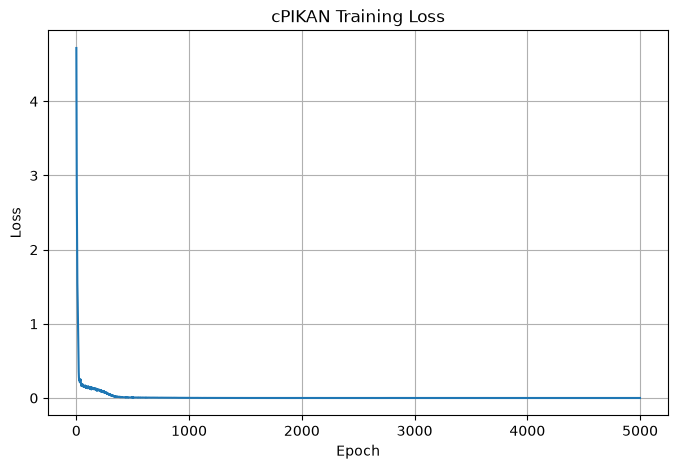

In [15]:
# Plotting the loss.

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("cPIKAN Training Loss")
plt.grid(True)
plt.show()

In [21]:
# Create evaluation grid
S_eval = torch.linspace(0, S_max, 100)
tau_eval = torch.linspace(0, T, 50)

S_grid, tau_grid = torch.meshgrid(S_eval, tau_eval, indexing="ij")

S_flat = S_grid.reshape(-1, 1)
tau_flat = tau_grid.reshape(-1, 1)

# Evaluate cPIKAN on the full grid
cpikan_model.eval()
with torch.no_grad():
    V_pred = cpikan_model(S_flat, tau_flat)

V_surface_cpikan = V_pred.reshape(S_grid.shape).detach().numpy()
S_grid_np = S_grid.numpy()
tau_grid_np = tau_grid.numpy()

# Comparing cPIKAN predictions with the exact Black-Scholes solution
V_exact_surface = black_scholes_call_grid(S_grid_np,tau_grid_np,K,r,sigma)
abs_error_surface_cpikan = np.abs(V_surface_cpikan - V_exact_surface)

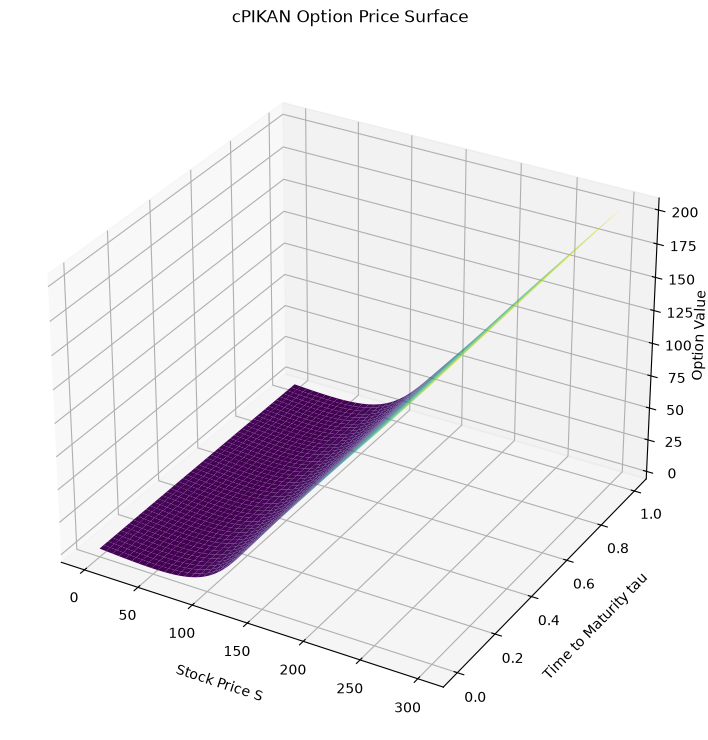

In [22]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(S_grid_np, tau_grid_np, V_surface_cpikan, cmap="viridis")

ax.set_title("cPIKAN Option Price Surface", pad=20)
ax.set_xlabel("Stock Price S", labelpad=10)
ax.set_ylabel("Time to Maturity tau", labelpad=10)
ax.set_zlabel("Option Value", labelpad=0)

fig.subplots_adjust(left=0.02, right=0.78, top=0.9, bottom=0.05)

plt.show()

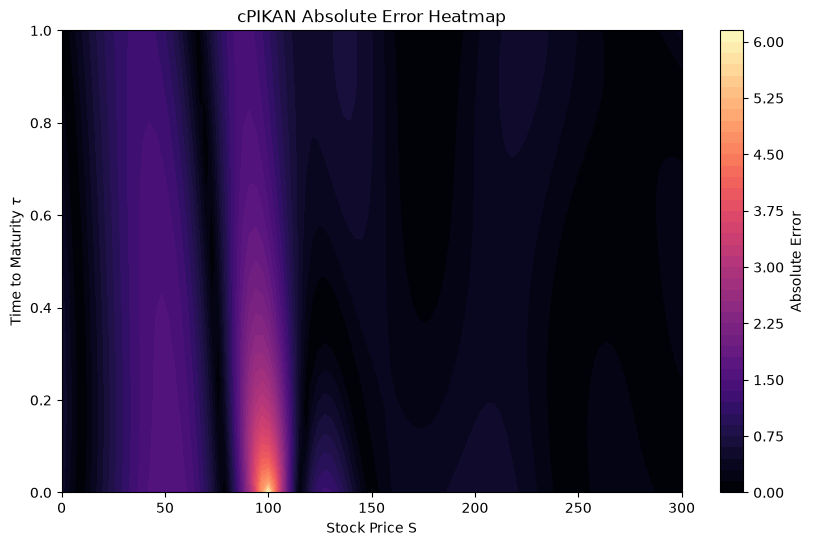

In [23]:
# Now, plot the absolute error heatmap between the cPIKAN predictions and the analytical solution.
# Plotting a heatmap as it provides a clear visual representation of the error distribution across the grid of stock prices and times to maturity.

plt.figure(figsize=(10, 6))

plt.contourf(S_grid_np, tau_grid_np, abs_error_surface_cpikan, levels=50, cmap="magma")
plt.colorbar(label="Absolute Error")

plt.title("cPIKAN Absolute Error Heatmap")
plt.xlabel("Stock Price S")
plt.ylabel("Time to Maturity $\\tau$")

plt.show()

In [25]:
# Plotting some key metrics for a more quantitative assessment of the cPIKAN's performance against the analytical solution.

metrics = error_summary(V_surface_cpikan, V_exact_surface)

metrics_table = pd.DataFrame({
    "Metric": metrics.keys(),
    "Value": metrics.values()
})

metrics_table

,Metric,Value
0,MSE,0.683066
1,RMSE,0.826478
2,MAE,0.564770
3,Max Abs Error,6.055150
4,Relative L2 Error,0.008552
